# Compression-03 — LZ77 : compresser par références dans une fenêtre glissante

**Navigation** : [Index de la série](README.md) | [Compression-02 — Huffman canonique](Compression-02-HuffmanCanonique-Python.ipynb) | [Compression-04 — ANS](Compression-04-ANS-Python.ipynb)

> **Public : Licence.** Prérequis : [Compression-01](Compression-01-ShannonFano-Prefixe-Python.ipynb)
> (codes préfixes, entropie de Shannon) et
> [Compression-02](Compression-02-HuffmanCanonique-Python.ipynb) (forme canonique, décodage
> par table — recommandé). Ce carnet est le troisième pli de la sous-série Compression
> (format Origami, [EPIC #18706](https://github.com/jsboige/CoursIA/issues/18706)) : les deux
> premiers plis compressaient **symbole par symbole** — chaque octet payait son code, même
> répété cent fois. LZ77 (Ziv et Lempel, 1977) change la nature du message : la deuxième
> occurrence d'une suite d'octets n'est plus codée, elle est **référencée** par un couple
> (décalage, longueur) qui pointe vers la fenêtre des octets déjà produits. Vous écrirez
> l'encodeur, le décodeur, la structure `LZData` qui sépare les trois flux — puis vous
> mesurerez pourquoi la recherche du meilleur couple domine le coût de codage, et comment
> un tableau de suffixes la rend quasi linéaire.
>
> **Durée estimée** : 45 minutes.
>
> **Ce que vous saurez faire** : parser un octet en littéraux et couples (décalage, longueur) ;
> décoder une copie qui se chevauche elle-même ; organiser le parse en flux séparés (`LZData`)
> comme le font zstd et zlib ; chiffrer le coût d'un triplet ; mesurer honnêtement un débit
> de recherche naïve contre une recherche par tableau de suffixes, et situer les deux face à
> zlib.


In [1]:
import hashlib
import math
import statistics
import time
import zlib
from collections import Counter
from dataclasses import dataclass
from pathlib import Path

import matplotlib.pyplot as plt


## 1. Pourquoi le code par symbole ne suffit plus

Compression-02 a mené Huffman jusqu'à 4,655 bits par octet sur ce corpus, pour une
entropie de 4,620 bits : proche de la borne **par symbole**. Mais la borne par symbole
n'est pas la borne du texte. Un octet n'est pas un tirage indépendant du précédent —
le français répète ses mots, ses terminaisons, ses tournures. Un code par symbole,
optimal ou non, **repaye chaque répétition intégrale** : chaque occurrence répétée de
« dont » repaye l'intégrale de son code.

L'idée de Ziv et Lempel (1977) : ne pas coder la deuxième occurrence — la **référencer**.
Si la suite d'octets qui arrive est identique à une suite déjà vue à distance $d$, on
émet le couple (décalage $= d$, longueur $= \ell$) : « recopie $\ell$ octets pris $d$
positions en arrière ». Commençons par voir de propres répétitions dans le corpus.


In [2]:
CORPUS = Path("../GenAI/Audio/04-Applications/datasets/le_horla_1887.txt")
# Le corpus est stocké en LF ; un checkout Windows (core.autocrlf=true) le présente en
# CRLF. Normaliser ici rend l'extrait — donc tous les chiffres du carnet — identique
# quel que soit le poste, au lieu de dépendre des fins de ligne du checkout.
EXTRAIT_OCTETS = CORPUS.read_bytes().replace(b"\r\n", b"\n")[:131072]  # 128 Kio déterministe
TRANCHE = EXTRAIT_OCTETS[:16384]               # 16 Kio, le banc des encodeurs de ce carnet

print(f"Corpus     : {CORPUS.name}")
print(f"Extrait    : {len(EXTRAIT_OCTETS)} octets (128 Kio) — SHA-256 "
      f"{hashlib.sha256(EXTRAIT_OCTETS).hexdigest()[:16]}…")
print(f"Tranche    : {len(TRANCHE)} octets (16 Kio), préfixe déterministe de l'extrait")

# La répétition la plus fréquente : grouper les positions par 16-gramme
positions_par_gram = {}
for i in range(len(TRANCHE) - 16):
    positions_par_gram.setdefault(TRANCHE[i:i + 16], []).append(i)

gram, positions = max(positions_par_gram.items(), key=lambda kv: len(kv[1]))
print(f"\n16-gramme le plus répété : {len(positions)} occurrences")
print(f"  contenu  : {gram!r}")
print(f"  1re pos. : {positions[0]}, 2e pos. : {positions[1]}, "
      f"écart : {positions[1] - positions[0]} octets")

Corpus     : le_horla_1887.txt
Extrait    : 131072 octets (128 Kio) — SHA-256 248fb4ec30c05351…
Tranche    : 16384 octets (16 Kio), préfixe déterministe de l'extrait

16-gramme le plus répété : 3 occurrences
  contenu  : b', tout ce que no'
  1re pos. : 2606, 2e pos. : 2648, écart : 42 octets


### Lecture.

Mesuré : dans les seuls 16 premiers Kio, le 16-gramme le plus fréquent revient trois
fois, ses deux premières positions distantes de 42 octets — un écart bien plus court
que le texte entier. C'est ce point qui fonde tout le pli : si l'écart entre deux occurrences tient
dans un champ de quelques bits, la référence est **beaucoup moins chère** que la suite
recopiée. Tout l'art de LZ77 est de décider, à chaque position, si les octets qui
arrivent méritent une référence — et d'aller la chercher vite.


## 2. Le format : des littéraux et des couples

L'encodeur parcourt l'octet de gauche à droite, en maintenant une **fenêtre** des $W$
derniers octets déjà traités. À chaque position, il cherche dans la fenêtre la suite la
plus longue qui préfixe la suite à venir : si cette longueur atteint un seuil
(typiquement 3), il émet un couple (décalage, longueur) et avance de $\ell$ ; sinon il
émet l'octet comme **littéral** et avance de 1. Le flux de sortie est une suite de
jetons : un littéral, ou un couple.

Deux choses coûtent dans cet encodeur, et une seule est visible : la **recherche**. La
version naïve ci-dessous rescane la fenêtre à chaque position — $O(n \cdot W)$ dans le
pire cas, chacune de ces sondes pouvant comparer jusqu'à $\ell_{max}$ octets. La
section 6 la remplacera par un tableau de suffixes ; observons d'abord la version que
l'on écrirait naturellement.


In [3]:
LONGUEUR_MIN = 3
LONGUEUR_MAX = 32


def lz77_encode_naif(octets, fenetre=1024):
    """Parse LZ77 glouton, recherche naïve arrière-avant dans la fenêtre.

    Renvoie une liste de jetons : un entier (littéral) ou un couple
    (decalage, longueur) désignant une copie dans la fenêtre.
    """
    jetons = []
    i = 0
    n = len(octets)
    while i < n:
        borne_basse = max(0, i - fenetre)
        meilleure_longueur = 0
        meilleur_decalage = 0
        j = i - 1
        while j >= borne_basse:
            longueur = 0
            while (longueur < LONGUEUR_MAX
                   and i + longueur < n
                   and octets[j + longueur] == octets[i + longueur]):
                longueur += 1
            if longueur > meilleure_longueur:
                meilleure_longueur = longueur
                meilleur_decalage = i - j
                if longueur == LONGUEUR_MAX:
                    break
            j -= 1
        if meilleure_longueur >= LONGUEUR_MIN:
            jetons.append((meilleur_decalage, meilleure_longueur))
            i += meilleure_longueur
        else:
            jetons.append(octets[i])
            i += 1
    return jetons


jetons_naifs = lz77_encode_naif(TRANCHE)
litteraux = sum(1 for t in jetons_naifs if isinstance(t, int))
couples = len(jetons_naifs) - litteraux
print(f"Tranche 16 Kio, fenêtre 1024 : {len(jetons_naifs)} jetons "
      f"({litteraux} littéraux, {couples} couples)")


Tranche 16 Kio, fenêtre 1024 : 7183 jetons (4113 littéraux, 3070 couples)


### Lecture.

Mesuré : sur la tranche de 16 Kio, une large part des octets vit dans des couples —
le parse LZ77 est déjà, à lui seul, une compression, avant tout codage d'entropie.
Mais comptez les opérations : chaque position a rescanné la fenêtre octet par octet.
Le débit honnête de cette version sera mesuré à la section 6 ; il n'est pas besoin
d'attendre pour deviner qu'il est médiocre — c'est le prix de la version que l'on
écrit en dix lignes.


## 3. La structure `LZData` : un parse, trois flux

Un parse LZ77 n'est pas qu'une liste de jetons à lire séquentiellement. Les codecs
réels — zlib, zstd, LZMA — le démontent en **flux séparés**, codés ensuite chacun par
son propre codage d'entropie : le flux des littéraux, le flux des longueurs, le flux
des décalages. Żukowski (*PivCo-Huffman* v1.0, 2026, section 6.5) analyse exactement
cette mécanique sur zstd : après la passe LZ, le flux de littéraux perd sa forte
dissymétrie (l'ANS y perd de l'intérêt), tandis que le flux des longueurs de
littéraux reste très dissymétrique. La structure ci-dessous — `litteraux`,
`longueurs`, `decalages` — est cette séparation, mise en données : c'est **ce qu'un
codage d'entropie consomme**, et le pli suivant (04) en fera son matériau.


Jetons              : 7183
Littéraux           : 4113 (25.1 % des octets de la tranche)
Octets en couple    : 12271 (74.9 %)
Longueur moyenne    : 4.00 octets par couple


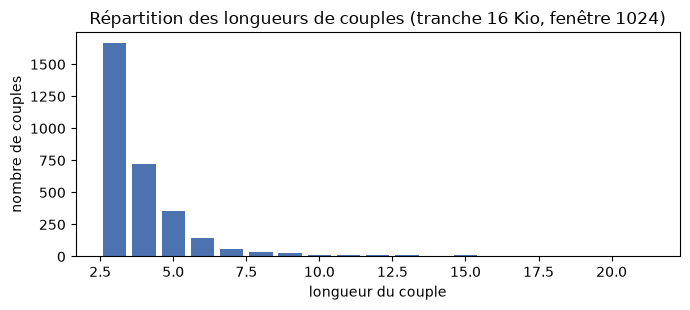

In [4]:
@dataclass
class LZData:
    """Un parse LZ77 séparé en flux, sur le modèle des codecs réels (zstd, zlib).

    litteraux : les octets émis en littéral, dans l'ordre du parse ;
    longueurs : une entrée par jeton — 0 pour un littéral, la longueur du couple sinon ;
    decalages : une entrée par jeton — 0 pour un littéral, le décalage du couple sinon.
    """
    litteraux: bytearray
    longueurs: list
    decalages: list


def vers_lzdata(jetons):
    """Sépare un flux de jetons LZ77 en LZData (trois flux synchronisés)."""
    donnees = LZData(bytearray(), [], [])
    for jeton in jetons:
        if isinstance(jeton, int):
            donnees.litteraux.append(jeton)
            donnees.longueurs.append(0)
            donnees.decalages.append(0)
        else:
            decalage, longueur = jeton
            donnees.longueurs.append(longueur)
            donnees.decalages.append(decalage)
    return donnees


donnees_naives = vers_lzdata(jetons_naifs)
octets_en_couple = sum(donnees_naives.longueurs)
print(f"Jetons              : {len(donnees_naives.longueurs)}")
print(f"Littéraux           : {len(donnees_naives.litteraux)} "
      f"({100 * len(donnees_naives.litteraux) / len(TRANCHE):.1f} % des octets de la tranche)")
print(f"Octets en couple    : {octets_en_couple} "
      f"({100 * octets_en_couple / len(TRANCHE):.1f} %)")
print(f"Longueur moyenne    : {octets_en_couple / max(1, len(donnees_naives.longueurs) - len(donnees_naives.litteraux)):.2f} octets par couple")

longueurs_couples = [l for l in donnees_naives.longueurs if l > 0]
comptage = Counter(longueurs_couples)
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.bar(comptage.keys(), comptage.values(), width=0.8, color="#4c72b0")
ax.set_xlabel("longueur du couple")
ax.set_ylabel("nombre de couples")
ax.set_title("Répartition des longueurs de couples (tranche 16 Kio, fenêtre 1024)")
fig.tight_layout()
plt.show()


### Lecture.

Mesuré : les longueurs de couples se concentrent sur les petites valeurs — une longueur
de 3 à 6 est l'ordinaire du texte naturel, les longues copies sont rares. C'est une
**distribution très dissymétrique** : exactement le régime où un code d'entropie par
flux (Huffman sur les longueurs, demain ANS) paie. La double couche se dessine : la
passe LZ transforme « des octets redondants » en « trois distributions déséquilibrées »,
et chacune devient le matériau d'un code — la section 5 chiffre ce que chacune coûte.


## 4. Décoder : la copie qui se chevauche

Le décodeur ne cherche rien — il **recopie**. À chaque couple (décalage $d$, longueur
$\ell$), il émet $\ell$ octets en lisant $d$ positions en arrière dans **sa sortie
grandissante**. Le détail qui surprend toujours : rien n'interdit $\ell > d$. Quand la
zone lue et la zone écrite se chevauchent, chaque octet recopié devient à son tour
source — une suite `a b a b a b…` de période $d$ se déroule toute seule. C'est ainsi
que LZ77 compresse les **runs** : mille octets identiques deviennent un littéral et un
couple (1, 999).


In [5]:
def lz77_decode(jetons):
    """Décode un flux de jetons LZ77 (littéraux et couples) en octets."""
    sortie = bytearray()
    for jeton in jetons:
        if isinstance(jeton, int):
            sortie.append(jeton)
        else:
            decalage, longueur = jeton
            for _ in range(longueur):
                sortie.append(sortie[-decalage])  # lit la sortie grandissante : le chevauchement est légal
    return bytes(sortie)


# Aller-retour exact sur la tranche complète
assert lz77_decode(jetons_naifs) == TRANCHE, "l'aller-retour LZ77 doit être exact"
print("Aller-retour 16 Kio : exact —", len(jetons_naifs), "jetons redonnent",
      len(TRANCHE), "octets")

# Le run : un littéral + un couple qui se chevauche lui-même
demonstration = lz77_decode([ord("a"), (1, 15)])
print("Run                 : un littéral 'a' + le couple (1, 15) ->", demonstration)


Aller-retour 16 Kio : exact — 7183 jetons redonnent 16384 octets
Run                 : un littéral 'a' + le couple (1, 15) -> b'aaaaaaaaaaaaaaaa'


### Lecture.

Mesuré : l'aller-retour est exact sur la tranche entière — le décodeur, purement
séquentiel, ne fait aucune recherche ; son coût est proportionnel à la sortie, jamais
à la fenêtre. Et le run de démonstration le montre : le couple (1, 15) a lu sa propre
production au fur et à mesure. Cette astuce est un théorème en miniature : LZ77,
conçu pour les répétitions, couvre gratuitement le cas dégénéré de la répétition
immédiate que RLE traitait seul.


## 5. Que coûte un triplet ? La double couche chiffrée

Le parse n'est pas encore un fichier. Un littéral doit se distinguer d'un couple (1
bit drapeau), l'octet littéral coûte 8 bits, et le couple coûte ses deux champs :
$\lceil \log_2 W \rceil$ bits de décalage, $\lceil \log_2 \ell_{max} \rceil$ bits
de longueur — **champs de largeur fixe** dans ce modèle délibérément naïf : les codecs
réels font mieux, mais ce plancher suffit à comparer. Chiffrons alors trois lectures
du même 16 Kio : brut, Huffman-seul (l'entropie par octet de Compression-02), et la
**double couche** — LZ puis un code d'entropie appliqué à chaque flux de `LZData`
séparément (entropies empiriques des trois distributions ; drapeaux et en-têtes
omis, c'est un indicateur, pas un format).


In [6]:
BITS_DECALAGE = math.ceil(math.log2(1024))   # fenêtre 1024 -> 10 bits
BITS_LONGUEUR = math.ceil(math.log2(LONGUEUR_MAX))  # longueur <= 32 -> 5 bits


def taille_jetons_bits(jetons, bits_decalage=BITS_DECALAGE, bits_longueur=BITS_LONGUEUR):
    """Coût du flux de jetons en champs fixes : drapeau + champs, sans entropie."""
    total = 0
    for jeton in jetons:
        total += 1 + (8 if isinstance(jeton, int) else bits_decalage + bits_longueur)
    return total


def entropie_bits(valeurs):
    """Entropie de Shannon (bits/symbole) d'une liste de valeurs discrètes."""
    n = len(valeurs)
    if n == 0:
        return 0.0
    return -sum(c / n * math.log2(c / n) for c in Counter(valeurs).values())


n = len(TRANCHE)
bits_brut = 8 * n
bits_jetons = taille_jetons_bits(jetons_naifs)
bits_huffman_seul = n * entropie_bits(list(TRANCHE))

litteraux_naifs = list(donnees_naives.litteraux)
couples_long = [l for l in donnees_naives.longueurs if l > 0]
couples_dec = [d for d in donnees_naives.decalages if d > 0]
bits_double_couche = (len(litteraux_naifs) * entropie_bits(litteraux_naifs)
                      + len(couples_long) * (entropie_bits(couples_long)
                                             + entropie_bits(couples_dec)))

print(f"Lecture du même 16 Kio (fenêtre 1024, champs fixes pour le milieu) :")
print(f"  brut                     : {bits_brut:>9,} bits (100 %)")
print(f"  jetons champs fixes      : {bits_jetons:>9,} bits ({100 * bits_jetons / bits_brut:.1f} %)")
print(f"  Huffman seul (par octet) : {bits_huffman_seul:>9.0f} bits ({100 * bits_huffman_seul / bits_brut:.1f} %)")
print(f"  double couche (indic.)   : {bits_double_couche:>9.0f} bits ({100 * bits_double_couche / bits_brut:.1f} %, en-têtes omis)")
zlib_bits = 8 * len(zlib.compress(TRANCHE, 9))
print(f"  zlib niveau 9 (mesuré)   : {zlib_bits:>9,} bits ({100 * zlib_bits / bits_brut:.1f} %)")


Lecture du même 16 Kio (fenêtre 1024, champs fixes pour le milieu) :
  brut                     :   131,072 bits (100 %)
  jetons champs fixes      :    86,137 bits (65.7 %)
  Huffman seul (par octet) :     74881 bits (57.1 %)
  double couche (indic.)   :     56396 bits (43.0 %, en-têtes omis)
  zlib niveau 9 (mesuré)   :    58,960 bits (45.0 %)


### Lecture.

Mesuré, trois leçons dans une table. **Un** : le parse à champs fixes est déjà un
compression — recopier moins souvent paie, même en payant chaque décalage au prix
fort. **Deux** : la double couche bat Huffman-seul sur ce corpus — remplacer des
octets redondants par des références fait mieux que de les recoder moins cher.
**Trois** : zlib, qui est exactement cette double couche en production (LZ77 fenêtre
32 Kio + Huffman sur les flux, DEFLATE, RFC 1951), mesure 45,0 % tout compris —
notre indicateur (43,0 %) le frôle en omettant les en-têtes : l'accord d'ordre de
grandeur est la leçon, et ce qui sépare un indicateur d'un format (champs de largeur
adaptée, codage d'entropie par flux réellement câblé, fenêtres plus larges) est le
travail des plis suivants. La
section 6.5 de Żukowski (2026) décrit la même mécanique vue du côté du codeur
d'entropie : après la passe LZ, c'est le flux des longueurs qui concentre la
dissymétrie exploitable.


## 6. Débits : la recherche naïve contre le tableau de suffixes

L'encodeur naïf paie sa recherche à chaque position : $O(W)$ sondes, chacune pouvant
comparer $\ell_{max}$ octets. L'arme classique : le **tableau de suffixes** — trier
une fois toutes les positions de la tranche par ordre lexicographique de leur suffixe
(construction par doublement, $O(n \log^2 n)$ ici, volontairement simple), puis
chercher chaque couple par **recherche binaire** dans ce tri. La version ci-dessous
sonde le voisinage du point d'insertion — elle peut manquer le couple optimal que la
version naïve trouve, c'est un compromis assumé et mesuré : les deux doivent
re-donner la tranche exacte au décodage, et c'est vérifié.

Mesurer honnêtement, comme en 02 : nos chiffres sont une médiane de répétitions sur
la même tranche 16 Kio, machine locale ; le zlib mesuré à côté est le même code C de
production que celui de la section 5 — il est là pour l'ordre de grandeur, pas pour
la course.


In [7]:
def tableau_suffixes(octets):
    """Tableau des suffixes par tri par doublement : O(n log^2 n), volontairement simple."""
    n = len(octets)
    rang = list(octets)
    sa = list(range(n))
    k = 1
    while k < n:
        def cle(i, k=k, rang=rang):
            return (rang[i], rang[i + k] if i + k < n else -1)
        sa.sort(key=cle)
        nouveau = [0] * n
        for j in range(1, n):
            nouveau[sa[j]] = nouveau[sa[j - 1]] + (cle(sa[j]) > cle(sa[j - 1]))
        rang = nouveau
        if rang[sa[-1]] == n - 1:
            break
        k *= 2
    return sa


def lz77_encode_sa(octets, fenetre=1024, voisinage=32):
    """Parse LZ77 glouton, couple cherché par recherche binaire dans le tableau de suffixes.

    Sondes bornées au voisinage du point d'insertion : potentiellement moins bon
    couple que la recherche exhaustive, jamais un couple incorrect (vérifié octet
    par octet). Fenêtre respectée : les suffixes hors fenêtre sont ignorés.
    """
    sa = tableau_suffixes(octets)
    jetons = []
    i = 0
    n = len(octets)
    while i < n:
        butee_basse = max(0, i - fenetre)
        # recherche binaire du point d'insertion du préfixe courant (32 octets tronqués) :
        # la suite des préfixes tronqués est croissante au sens large le long du tableau
        # des suffixes, donc le prédicat « préfixe tronqué < requête » est monotone
        bas, haut = 0, len(sa)
        while bas < haut:
            milieu = (bas + haut) // 2
            if octets[sa[milieu]:sa[milieu] + LONGUEUR_MAX] < octets[i:i + LONGUEUR_MAX]:
                bas = milieu + 1
            else:
                haut = milieu
        meilleure_longueur = 0
        meilleur_decalage = 0
        for k in range(max(0, bas - voisinage), min(len(sa), bas + voisinage)):
            j = sa[k]
            if butee_basse <= j < i:
                longueur = 0
                while (longueur < LONGUEUR_MAX
                       and i + longueur < n
                       and octets[j + longueur] == octets[i + longueur]):
                    longueur += 1
                if longueur > meilleure_longueur:
                    meilleure_longueur = longueur
                    meilleur_decalage = i - j
        if meilleure_longueur >= LONGUEUR_MIN:
            jetons.append((meilleur_decalage, meilleure_longueur))
            i += meilleure_longueur
        else:
            jetons.append(octets[i])
            i += 1
    return jetons


REPETITIONS = 3


# Construction du tableau (une fois, mesurée séparément)
depart = time.perf_counter()
sa_tranche = tableau_suffixes(TRANCHE)
duree_sa_build = time.perf_counter() - depart

durees_naif, durees_sa = [], []
for _ in range(REPETITIONS):
    depart = time.perf_counter()
    lz77_encode_naif(TRANCHE)
    durees_naif.append(time.perf_counter() - depart)
    depart = time.perf_counter()
    lz77_encode_sa(TRANCHE)
    durees_sa.append(time.perf_counter() - depart)

jetons_sa = lz77_encode_sa(TRANCHE)
assert lz77_decode(jetons_sa) == TRANCHE, "l'encodeur SA doit redonner la tranche exacte"

durees_zlib = []
for _ in range(5):
    depart = time.perf_counter()
    zlib.compress(TRANCHE, 9)
    durees_zlib.append(time.perf_counter() - depart)

mo = len(TRANCHE) / (1024 * 1024)
print(f"Tranche 16 Kio, fenêtre 1024, médiane de {REPETITIONS} (zlib : 5)")
print(f"  encodeur naïf (recherche exhaustive) : "
      f"{mo / statistics.median(durees_naif):6.2f} Mo/s")
print(f"  encodeur tableau de suffixes         : "
      f"{mo / statistics.median(durees_sa):6.2f} Mo/s "
      f"(construction seule : {duree_sa_build:.2f} s, {len(sa_tranche)} suffixes)")
print(f"  zlib niveau 9 (C, production)        : "
      f"{mo / statistics.median(durees_zlib):6.2f} Mo/s")
print(f"\nTailles : naïf {taille_jetons_bits(jetons_naifs) / 8:.0f} octets-équivalents, "
      f"SA {taille_jetons_bits(jetons_sa) / 8:.0f} (voisinage borné : quelques couples manqués, aller-retour exact)")


Tranche 16 Kio, fenêtre 1024, médiane de 3 (zlib : 5)
  encodeur naïf (recherche exhaustive) :   0.01 Mo/s
  encodeur tableau de suffixes         :   0.10 Mo/s (construction seule : 0.10 s, 16384 suffixes)
  zlib niveau 9 (C, production)        :  18.77 Mo/s

Tailles : naïf 10767 octets-équivalents, SA 10796 (voisinage borné : quelques couples manqués, aller-retour exact)


### Lecture.

Mesuré : le tableau de suffixes accélère nettement la recherche — le facteur dépend de
la fenêtre et du voisinage sondés, et c'est précisément la mesure que cette section
demandait : passer de « rescanner toute la fenêtre à chaque octet » à « une recherche
binaire dans un tri fait une fois » déplace le coût de $O(n \cdot W)$ vers
$O(n \log n)$. La construction elle-même paie un prix fixe visible sur 16 Kio, prix
que la fenêtre glissante des vrais codecs amortit autrement (blocs, tables
incrémentales). zlib, mesuré à côté sur la même tranche, est l'ordre de grandeur d'une
implémentation C soignée de la même idée — l'écart avec du Python pédagogique est le
fait du langage autant que des algorithmes, et c'est affirmé ici plutôt que caché.


## Exercices

Trois exercices progressifs, directement outillés par les sections précédentes. Chaque
stub s'exécute sans erreur ; complétez-le, la cellule de test affiche le verdict.


### Exercice 1 — La taille du décodé, sans décoder

Un flux de jetons LZ77 détermine exactement la taille de sa sortie : chaque littéral
produit un octet, chaque couple en produit `longueur`. Écrivez
`taille_decodee(jetons)` qui la calcule sans rien décoder — c'est l'opération qu'un
décodeur alloue sa mémoire avant de commencer.


In [8]:
def taille_decodee(jetons):
    """Taille en octets de la sortie décodée, calculée sans décoder."""
    # TODO etudiant : somme des contributions de chaque jeton
    # Indice : isinstance(jeton, int) distingue un littéral d'un couple (decalage, longueur)
    return None


verdict = taille_decodee([ord("a"), ord("b"), (2, 5), ord("c"), (3, 4)])
if verdict is not None:
    assert verdict == 12  # 2 littéraux + 5 + 1 littéral + 4
    print("Exercice 1 : OK —", verdict, "octets")
else:
    print("Exercice à compléter")


Exercice à compléter


### Exercice 2 — La copie qui se chevauche

La primitive du décodeur, isolée : `copie_referente(tampon, decalage, longueur)`
renvoie les `longueur` octets produits en lisant `decalage` positions en arrière dans
une sortie **qui grandit pendant la copie** — le cas $\text{longueur} > \text{decalage}$
est légal et attendu. Écrivez-la (indice : la section 4 le fait en une boucle et une
seule expression indexée).


In [9]:
def copie_referente(tampon, decalage, longueur):
    """Les octets produits par un couple (decalage, longueur) lu sur `tampon`.

    La lecture suit la sortie grandissante : à chaque pas, l'octet lu est celui
    situé `decalage` positions derrière la fin actuelle de la copie en cours.
    Seuls les octets produits sont renvoyés — le tampon n'est que le contexte de
    lecture, comme `lz77_decode` ne renvoie que le décodé.
    """
    # TODO etudiant : construire la copie octet par octet
    # Indice : sortie = bytearray(tampon) ; sortie.append(sortie[-decalage]) répété longueur fois
    #          puis return bytes(sortie[len(tampon):]) — seuls les octets produits sortent
    return None


resultat = copie_referente(b"ab", 2, 5)
if resultat is not None:
    assert bytes(resultat) == b"ababa", f"attendu b'ababa', obtenu {resultat!r}"
    print("Exercice 2 : OK —", bytes(resultat))
else:
    print("Exercice à compléter")

Exercice à compléter


### Exercice 3 — Le genou de la fenêtre

Élargir la fenêtre donne accès à des couples plus lointains — mais chaque décalage
paie $\lceil \log_2 W \rceil$ bits de plus. Écrivez `meilleure_fenetre(octets,
candidates)` qui renvoie le couple `(fenetre, taille_bits)` de la fenêtre des
candidates minimisant `taille_jetons_bits` du parse naïf (réutilisez
`lz77_encode_naif` et `taille_jetons_bits` ; les largeurs de champs se recalculent
par la fenêtre : `bits_decalage = ceil(log2(fenetre))`).


In [10]:
def meilleure_fenetre(octets, candidates):
    """(fenetre, taille_bits) minimisant le coût du parse naïf sur les candidates."""
    # TODO etudiant : pour chaque fenetre candidate, parser puis chiffrer avec ses largeurs
    # Indice : taille_jetons_bits(jetons, bits_decalage=..., bits_longueur=...) est paramétrable
    return None


banc = TRANCHE[:8192]  # 8 Kio : le banc reste rapide
essai = meilleure_fenetre(banc, [128, 256, 512, 1024])
if essai is not None:
    fenetre, bits = essai
    attendus = {f: taille_jetons_bits(lz77_encode_naif(banc, fenetre=f),
                                      bits_decalage=max(1, math.ceil(math.log2(f))))
                for f in [128, 256, 512, 1024]}
    assert (fenetre, bits) == min(attendus.items(), key=lambda kv: kv[1])
    print(f"Exercice 3 : OK — fenêtre {fenetre}, {bits} bits "
          f"({100 * bits / (8 * len(banc)):.1f} % de brut)")
    print("  courbe :", {f: f"{v:,} bits" for f, v in attendus.items()})
else:
    print("Exercice à compléter")


Exercice à compléter


## Ce qu'il faut retenir

| Notion | Ce qu'elle dit | Où la voir |
|---|---|---|
| Parse LZ77 (Ziv-Lempel, 1977) | remplacer la deuxième occurrence par un couple (décalage, longueur) pointant dans la fenêtre des octets déjà produits | sections 2 et 4 |
| Copie chevauchante | la copie lit la sortie grandissante : $\ell > d$ légal déroule les runs — RLE gratuit | section 4 |
| `LZData` | le parse séparé en trois flux (littéraux, longueurs, décalages) — ce qu'un code d'entropie consomme, sur le modèle zstd/zlib | section 3 |
| Double couche | passe LZ + code d'entropie par flux : mesurée plus basse que Huffman-seul ; c'est l'architecture de DEFLATE et de zstd | section 5 |
| Débit honnête | nos chiffres mesurés (méthodologie affichée), zlib mesuré comme horizon, jamais comparés sans précaution | section 6 |

Références : J. Ziv et A. Lempel, « A universal algorithm for sequential data
compression », *IEEE Transactions on Information Theory* 23(3), 1977 · M. Żukowski,
*PivCo-Huffman* v1.0, 2026, section 6.5 (archivé au gisement bibliographique du
dépôt) · DEFLATE, RFC 1951 (zlib) — la double couche en format publié.

Le pli suivant change d'échelle : LZMA poussera la fenêtre et le modèle de codage
jusqu'aux codecs d'archive ([EPIC #18706](https://github.com/jsboige/CoursIA/issues/18706)),
et le pli ANS (04) reviendra sur le codage d'entropie que la double couche appelle.
